# Exploratory Data Analysis (EDA) & Encoding
Mainly, this notebook covers EDA on the raw trace data and encoding it for use in other steps of the development process.
Also this notebook will compare the performance of using the both method, Which is more robust to go forward without losing any data in the process

In [2]:
import sys
import os
import time
import json
import pandas as pd
import numpy as np
from collections import Counter

sys.path.append("..")

# Import the function from the utils which will needed here
from utils import (
    stream_opcodes,
    count_opcodes_from_stream,
    build_opcode_vocab,
    encode_trace_to_npy,
    save_vocab,
    load_vocab,
    check_vocab_size,
    decode_trace_npy,
    load_encoded_trace
)

## Initializing the Paths

In [3]:
RAW_TRACES_DIR = "../sandbox/data/raw_traces"
MANIFEST_CSV = "../sandbox/data/manifest.csv"
ENCODED_DIR = "../sandbox/data/encoded_traces"
VOCAB_JSON = "../sandbox/data/vocab.json"

os.makedirs(ENCODED_DIR, exist_ok=True)

# Load the manifest CSV to get the metadata to use later
df_manifest = pd.read_csv(MANIFEST_CSV)
print(f"Manifest Loaded: {len(df_manifest)} rows")

# Get the list of raw trace files in the directory and sort them for processing
trace_files = sorted([
    os.path.join(RAW_TRACES_DIR, f)
    for f in os.listdir(RAW_TRACES_DIR)
    if f.endswith(".txt")
])
print(f"Raw trace files found: {len(trace_files)}")

Manifest Loaded: 260 rows
Raw trace files found: 260


----
## EDA using Raw Trace Streaming - Method 1
Each of the raw opcode trace file is streamed line by line using `stream_opcodes()` function. A single pass over each file simultaneously to improve the performance.

In [4]:
# Set the data structures to hold the global vocab, per file opcode counts, and streaming times
global_vocab = set()
per_file_counts = {}
stream_times = {}

MIN_OPCODE_COUNT = 10 # Filter threshold to removes likely malformed or truncated opcodes

print(f"Streaming {len(trace_files)} trace files...")
print("This will take a moment base on the given file sizes. The progress shown per 10 files\n")

total_start = time.time()

# Stream through each trace file count the opcodes and store the counts and elapsed time
for i, path in enumerate(trace_files, 1):
    filename = os.path.basename(path)
    t0 = time.time()

    counter = Counter()
    for opcode in stream_opcodes(path):
        counter[opcode] += 1

    elapsed = time.time() - t0
    stream_times[filename] = elapsed
    per_file_counts[filename] = counter

    if i % 10 == 0 or i == len(trace_files):
        done = time.time() - total_start
        print(f"  [{i:>3}/{len(trace_files)}]  elapsed: {done/60:.1f} min")

# Build global counts then filter by minimum threshold
global_counter = Counter()
for c in per_file_counts.values():
    global_counter.update(c)

# Filter the global counter to remove opcodes that are below the minimum threshold
removed = [op for op, count in global_counter.items() if count < MIN_OPCODE_COUNT]
global_vocab = {op for op, count in global_counter.items() if count >= MIN_OPCODE_COUNT}

total_stream_time = time.time() - total_start
print(f"\nStreaming Complete:  {total_stream_time/60:.1f} min total")
print(f"Raw Vocabulary Size: {len(global_counter)} distinct opcodes")
print(f"After Filtering (>={MIN_OPCODE_COUNT}): {len(global_vocab)} distinct opcodes")
print(f"Removed {len(removed)} opcode(s): {removed}")

Streaming 260 trace files...
This will take a moment base on the given file sizes. The progress shown per 10 files

  [ 10/260]  elapsed: 14.1 min
  [ 20/260]  elapsed: 26.5 min
  [ 30/260]  elapsed: 38.3 min
  [ 40/260]  elapsed: 50.9 min
  [ 50/260]  elapsed: 64.0 min
  [ 60/260]  elapsed: 77.0 min
  [ 70/260]  elapsed: 89.3 min
  [ 80/260]  elapsed: 102.7 min
  [ 90/260]  elapsed: 115.6 min
  [100/260]  elapsed: 128.6 min
  [110/260]  elapsed: 141.6 min
  [120/260]  elapsed: 155.2 min
  [130/260]  elapsed: 168.7 min
  [140/260]  elapsed: 184.4 min
  [150/260]  elapsed: 198.0 min
  [160/260]  elapsed: 210.1 min
  [170/260]  elapsed: 223.6 min
  [180/260]  elapsed: 236.8 min
  [190/260]  elapsed: 251.6 min
  [200/260]  elapsed: 264.8 min
  [210/260]  elapsed: 277.6 min
  [220/260]  elapsed: 289.2 min
  [230/260]  elapsed: 301.5 min
  [240/260]  elapsed: 313.9 min
  [250/260]  elapsed: 326.2 min
  [260/260]  elapsed: 340.2 min

Streaming Complete:  340.3 min total
Raw Vocabulary Size: 

### Opcode Vocabulary
The full set of distinct x86 opcode mnemonics seen across all 260 files. `check_vocab_size` confirms the count is safely within the `int32` range used for encoding.

In [5]:
vocab = sorted(global_vocab)
check_vocab_size(vocab)

print(f"Vocabulary Size: {len(vocab)} distinct opcodes")
print(f"Opcodes List: {vocab}")

Vocabulary Size: 147464 distinct opcodes
Opcodes List: ['\x00', '\x00\x00', '2MOV', '2POP', '2S', '2SD', '2SS', 'A', 'AA', 'AACMP', 'AAD', 'AADC', 'AADCASTB', 'AADD', 'AADDA', 'AADDADD', 'AADDAND', 'AADDC', 'AADDCALL_NEAR', 'AADDCMP', 'AADDH', 'AADDJ', 'AADDJBE', 'AADDJMP', 'AADDJMPR', 'AADDJNZ', 'AADDJZ', 'AADDL', 'AADDLEA', 'AADDM', 'AADDMMOV', 'AADDMOV', 'AADDMOVSXD', 'AADDMOVZX', 'AADDN', 'AADDNEA', 'AADDNOP', 'AADDNOPR', 'AADDOV', 'AADDP', 'AADDPOP', 'AADDPUSH', 'AADDR', 'AADDRET_NEAR', 'AADDSHL', 'AADDSHR', 'AADDSUB', 'AADDT', 'AADDTEST', 'AADDV', 'AADDXOR', 'AADD_LOCK', 'AADD_NEAR', 'AAEA', 'AAEST', 'AAL', 'AALEA', 'AALL_NEAR', 'AAMOV', 'AAMP', 'AAN', 'AAND', 'AANDADD', 'AANDAND', 'AANDC', 'AANDCALL_NEAR', 'AANDCMP', 'AANDJ', 'AANDJMP', 'AANDJNZ', 'AANDJZ', 'AANDLEA', 'AANDM', 'AANDMOV', 'AANDMOVSXD', 'AANDMOVZX', 'AANDN', 'AANDNOP', 'AANDNOPR', 'AANDPOP', 'AANDPUSH', 'AANDRET_NEAR', 'AANDSHL', 'AANDSUB', 'AANDTEST', 'AANOP', 'AAOP', 'AAOR', 'AAOV', 'AAP', 'AAPS', 'AAR', 'AARET_

### Crosscheck opcode counts with the manifest data

The manifest already has `opcode_count` from the log's "Opcodes recorded" line. Comparing these with the actual line counts from the streaming pass confirms the raw trace files are complete and uncorrupted.

In [6]:
stream_counts = {
    fname: sum(c.values())
    for fname, c in per_file_counts.items()
}

df_cross = df_manifest[["filename", "opcode_count"]].copy()
df_cross["stream_count"] = df_cross["filename"].map(stream_counts)
df_cross["match"] = df_cross["opcode_count"] == df_cross["stream_count"]

mismatches = df_cross[~df_cross["match"].fillna(False)]
print(f"Files with matching counts: {df_cross['match'].sum()}")
print(f"Mismatches or missing count: {len(mismatches)}")

if len(mismatches):
    print("\nMismatched Files:")
    print(mismatches)

Files with matching counts: 0
Mismatches or missing count: 260

Mismatched Files:
                                              filename  opcode_count  \
0    GommeHD.net-Java-API-2.2.0-jar-with-dependenci...     260820917   
1                                     abbot-0.13.0.jar     254041267   
2                              activecluster-4.0.2.jar     192207700   
3                                  activemq-4.0-M1.jar     250481273   
4                               activemq-all-6.2.6.jar     253860779   
..                                                 ...           ...   
255                         xercesjarv-20020712-DG.jar     143908087   
256                               xml-resolver-1.2.jar     190239295   
257                                      xom-1.4.5.jar     182326574   
258                                xsdlib-20050913.jar     201645585   
259                                  ymsg-test-0.6.jar     215564901   

     stream_count  match  
0             NaN  False  

### Global Opcode Frequency Distribution

Analyze the frequency across all 260 files, which opcodes dominate the instruction mix. This clearly shows later feature engineering decisions.

This is a summary table only for this stage, plots will be created on later step.

In [7]:
global_counter = Counter()

for count in per_file_counts.values():
    global_counter.update(count)

df_freq = pd.DataFrame(
    global_counter.most_common(),
    columns=["opcode", "total_count"]
)

df_freq["proportion"] = df_freq["total_count"] / df_freq["total_count"].sum()

print(f"Top 20 most frequent opcodes across all {len(trace_files)} files:\n")
print(df_freq.head(20).to_string(index=False))

Top 20 most frequent opcodes across all 260 files:

   opcode  total_count  proportion
      MOV  16538400081    0.309586
      CMP   4180546171    0.078257
      ADD   2976016600    0.055709
       JZ   2965189532    0.055506
     PUSH   2692181522    0.050396
     TEST   2576919704    0.048238
      POP   2009295864    0.037612
      LEA   1822813697    0.034122
      JNZ   1799693030    0.033689
    MOVZX   1649333231    0.030874
      JMP   1477520336    0.027658
      NOP   1040790045    0.019483
      AND    991303539    0.018556
      SUB    965821932    0.018079
 RET_NEAR    874149689    0.016363
CALL_NEAR    861413468    0.016125
   MOVSXD    643206426    0.012040
    STOSB    582842973    0.010910
      SHR    581693942    0.010889
      XOR    561040114    0.010502


#### Bottom of the distribution to list the rarest opcodes

In [8]:
print("Rarest 20 opcodes (lowest global frequency):\n")
print(df_freq.tail(20).to_string(index=False))

Rarest 20 opcodes (lowest global frequency):

              opcode  total_count   proportion
 MOVCALL_NEARADCNROP            1 1.871924e-11
      MOVMMOVSUBMOVS            1 1.871924e-11
PUNPCKLQDQSUBCMOVAPS            1 1.871924e-11
            ADD_LOCG            1 1.871924e-11
             NEARLJB            1 1.871924e-11
        MNOPJBJNBMOV            1 1.871924e-11
          USHCMPVMOV            1 1.871924e-11
          OPUSHVZMOV            1 1.871924e-11
          JBMOVOXORO            1 1.871924e-11
      IMULCJMP_NEARM            1 1.871924e-11
            VNOPNOPA            1 1.871924e-11
          CMOVLEMOVR            1 1.871924e-11
    TESTRET_NEAR_JZA            1 1.871924e-11
      MOVTEPUSHJNMOV            1 1.871924e-11
             MRRNEAR            1 1.871924e-11
    POPMOJLERET_NEAR            1 1.871924e-11
  LEACANOPMONOPMOMOV            1 1.871924e-11
        CDMCALL_NEAR            1 1.871924e-11
         LEASULEASHR            1 1.871924e-11
          MOBT

### Check per file trace length distribution

How much do the 260 files vary in total opcode counts, large variation matters for normalization and some file have 260M opcodes and some are 50M opcodes, this should contribute comparable feature vectors, not be dominated by raw size.

In [9]:
df_lengths = pd.DataFrame({
    "filename": list(stream_counts.keys()),
    "opcode_count": list(stream_counts.values()),
})

print(df_lengths["opcode_count"].describe().apply(lambda x: f"{x:,.0f}"))

count            260
mean     205,465,254
std       36,698,896
min      133,612,087
25%      189,471,563
50%      195,087,740
75%      246,906,369
max      277,399,953
Name: opcode_count, dtype: str


### Streaming Timing Summary

Time taken per file using raw text streaming, the baseline for the performance comparison with Method 2 (Encoded Array) later.

In [10]:
df_timing = pd.DataFrame({
    "filename": list(stream_times.keys()),
    "stream_sec": list(stream_times.values()),
})

df_timing["opcodes"] = df_timing["filename"].map(stream_counts)
df_timing["lines_per_sec"] = (df_timing["opcodes"] / df_timing["stream_sec"]).astype(int)

print(f"Streaming Speed Summary (Method 1)")
print(df_timing["lines_per_sec"].describe().apply(lambda x: f"{x:,.0f}"))
print(f"\nTotal Streaming Time: {df_timing['stream_sec'].sum()/60:.1f} min")

Streaming Speed Summary (Method 1)
count          260
mean     2,620,273
std         66,363
min      2,255,467
25%      2,585,738
50%      2,640,778
75%      2,670,120
max      2,738,943
Name: lines_per_sec, dtype: str

Total Streaming Time: 340.2 min


### Save EDA Outputs into CSVs

Save the frequency table and timing results as CSVs so it can be used for later visualization and later notebooks can load them without re-streaming.

In [11]:
df_freq.to_csv("../sandbox/data/processed_outputs/global_opcode_freq.csv", index=False)
print("global_opcode_freq.csv file saved!")

df_lengths.to_csv("../sandbox/data/processed_outputs/per_file_lengths.csv", index=False)
print("per_file_lengths.csv file saved!")

df_timing.to_csv("../sandbox/data/processed_outputs/streaming_timing.csv", index=False)
print("streaming_timing.csv file saved!")

global_opcode_freq.csv file saved!
per_file_lengths.csv file saved!
streaming_timing.csv file saved!


----
## Encoding - Method 2

The vocabulary built in Method 1 is now used to encode each raw trace file into a compact `int32` NumPy array. This is the one-time resource cost that makes every later analysis fast.

The raw trace files are more than 1 GB text. Rereading them for every feature type (frequency, n-grams, Markov, sliding windows, etc) would multiply the resource cost by the number of feature types. Instead, encoding converts each file to a compact binary array, that can be loaded fully into RAM and processed entirely with vectorized NumPy operations, so no further text parsing needed.

The encoding is lossless, the original opcode sequence can be recovered exactly from the `.npy` file and using the `vocab.json` as the mapping file.

In [12]:
# Save the vocabs so every later notebook uses exactly the same mapping
save_vocab(vocab, VOCAB_JSON)
print(f"Vocabulary saved to {VOCAB_JSON}")
print(f"Total of {len(vocab)} opcodes")

vocab_to_id = {op: i for i, op in enumerate(vocab)}

Vocabulary saved to ../sandbox/data/vocab.json
Total of 147464 opcodes


### Encode All 260 Files (Safety Measures)

Each file is streamed once, encoded to `int32`, and written to `encoded_traces/`. Files already encoded from a previous run are skipped, so this cell is safety measure to rerun if any of the file interrupted.

In [13]:
encode_times = {}
encode_counts = {}
skipped = 0
reencoded = 0

print(f"Encoding {len(trace_files)} files to {ENCODED_DIR}/\n")
total_start = time.time()

for i, path in enumerate(trace_files, 1):
    filename = os.path.basename(path)
    npy_name = filename.replace(".txt", ".npy")
    npy_path = os.path.join(ENCODED_DIR, npy_name)

    # Skip if already encoded as int32, safe to rerun
    if os.path.exists(npy_path):
        arr = load_encoded_trace(npy_path, mmap=False)
        if arr.dtype == np.int32:
            skipped += 1
            encode_counts[filename] = len(arr)
            continue
        else:
            reencoded += 1
            print(f"Re-encoding {filename} from dtype {arr.dtype} to int32")

    t0 = time.time()
    n = encode_trace_to_npy(path, vocab_to_id, npy_path)
    elapsed = time.time() - t0

    encode_times[filename] = elapsed
    encode_counts[filename] = n

    if i % 10 == 0 or i == len(trace_files):
        done = time.time() - total_start
        print(f"  [{i:>3}/{len(trace_files)}]  elapsed: {done/60:.1f} min")

total_encode_time = time.time() - total_start
print(f"\nEncoding complete in {total_encode_time/60:.1f} min total")

if skipped:
    print(f" ({skipped} files skipped - already encoded as int32)")
if reencoded:
    print(f" ({reencoded} files re-encoded from an older dtype)")


Encoding 260 files to ../sandbox/data/encoded_traces/

  [ 10/260]  elapsed: 7.8 min
  [ 20/260]  elapsed: 14.8 min
  [ 30/260]  elapsed: 21.5 min
  [ 40/260]  elapsed: 29.1 min
  [ 50/260]  elapsed: 37.4 min
  [ 60/260]  elapsed: 44.9 min
  [ 70/260]  elapsed: 52.4 min
  [ 80/260]  elapsed: 60.3 min
  [ 90/260]  elapsed: 68.1 min
  [100/260]  elapsed: 75.7 min
  [110/260]  elapsed: 83.3 min
  [120/260]  elapsed: 91.1 min
  [130/260]  elapsed: 99.0 min
  [140/260]  elapsed: 107.7 min
  [150/260]  elapsed: 115.8 min
  [160/260]  elapsed: 122.9 min
  [170/260]  elapsed: 130.8 min
  [180/260]  elapsed: 138.6 min
  [190/260]  elapsed: 147.9 min
  [200/260]  elapsed: 156.0 min
  [210/260]  elapsed: 164.1 min
  [220/260]  elapsed: 171.1 min
  [230/260]  elapsed: 178.4 min
  [240/260]  elapsed: 185.5 min
  [250/260]  elapsed: 192.4 min
  [260/260]  elapsed: 200.1 min

Encoding complete in 200.1 min total


### Verify Encoding Is Lossless (Round Trip Check)

Decode one encoded file back to opcode strings and compare against the original raw text to confirm no data was lost in the process.

In [14]:
# Pick the first file for verification
sample_txt = trace_files[0]
sample_filename = os.path.basename(sample_txt)
sample_npy = os.path.join(ENCODED_DIR, sample_filename.replace(".txt", ".npy"))

# Read first N number of opcodes from the raw file
N = 100000
raw_sample = []

for opcode in stream_opcodes(sample_txt):
    raw_sample.append(opcode)
    if len(raw_sample) == N:
        break

# Decode first N from the .npy
decoded_sample = decode_trace_npy(sample_npy, vocab)[:N]

match = raw_sample == decoded_sample
print(f"Round trip check on '{sample_filename}' (First {N} opcodes): {'PASS' if match else 'FAIL'}")

if not match:
    # Find where they got an issue
    for j, (a, b) in enumerate(zip(raw_sample, decoded_sample)):
        if a != b:
            print(f"  First mismatch at position {j}: raw = '{a}' decoded = '{b}'")
            break

Round trip check on 'GommeHD.net-Java-API-2.2.0-jar-with-dependencies.txt' (First 100000 opcodes): PASS


### File Size Comparison

Raw `.txt` vs encoded `.npy` for each file, shows the storage saving from encoding.

In [15]:
size_rows = []

for path in trace_files:
    filename = os.path.basename(path)
    npy_path = os.path.join(ENCODED_DIR, filename.replace(".txt", ".npy"))
    txt_mb = os.path.getsize(path) / 1e6
    npy_mb = os.path.getsize(npy_path) / 1e6 if os.path.exists(npy_path) else None
    size_rows.append({"filename": filename, "txt_mb": txt_mb, "npy_mb": npy_mb})

df_sizes = pd.DataFrame(size_rows)
df_sizes["reduction"] = (1 - df_sizes["npy_mb"] / df_sizes["txt_mb"]).round(3)

print("File Size Summary")
print(df_sizes[["txt_mb", "npy_mb", "reduction"]].describe().round(2))
print(f"\nTotal Raw Text: {df_sizes['txt_mb'].sum():.1f} MB")
print(f"Total Encoded:  {df_sizes['npy_mb'].sum():.1f} MB")
print(f"Average Reduction: {df_sizes['reduction'].mean()*100:.1f}%")

File Size Summary
        txt_mb   npy_mb  reduction
count   260.00   260.00     260.00
mean    911.86   821.86       0.10
std     162.25   146.80       0.00
min     592.95   534.45       0.09
25%     841.85   757.89       0.10
50%     866.78   780.35       0.10
75%    1093.42   987.63       0.10
max    1228.45  1109.60       0.12

Total Raw Text: 237084.1 MB
Total Encoded:  213683.9 MB
Average Reduction: 9.9%


### Method Comparison - Streaming vs Encoded Array

The core experimental comparison. For the files where both timing measurements exist, this shows the throughput difference between Method 1 (Raw Text Streaming) and Method 2 (Encoding).

NOTE: That after this one-time encoding resource cost, every later feature computation (n-grams, Markov matrices, sliding windows, etc) works from the `.npy` files and is near instant relative to either streaming approach.

In [ ]:
# Build a comparison table for files where it has both timings
common = set(stream_times.keys()) & set(encode_times.keys())

if common:
    rows = []
    
    for fname in sorted(common):
        n_ops    = stream_counts.get(fname, 0)
        s_time   = stream_times[fname]
        e_time   = encode_times[fname]
        
        rows.append({
            "filename": fname,
            "opcodes": n_ops,
            "stream_sec":  round(s_time, 2),
            "encode_sec":  round(e_time, 2),
            "stream_rate": int(n_ops / s_time) if s_time > 0 else 0,
            "encode_rate": int(n_ops / e_time) if e_time > 0 else 0,
        })

    df_compare = pd.DataFrame(rows)

    print("Method Comparison (Files processed in both passes):\n")
    print(f"  Streaming - AVG Rate: {df_compare['stream_rate'].mean():>10,.0f} opcodes/sec")
    print(f"  Encoding - AVG Rate: {df_compare['encode_rate'].mean():>10,.0f} opcodes/sec")
    print(f"  Encoding is around {df_compare['encode_rate'].mean()/df_compare['stream_rate'].mean():.1f}x faster than streaming")

    df_compare.to_csv("../sandbox/data/processed_outputs/method_comparison.csv", index=False)
    print("\nSaved to method_comparison.csv")
    
else:
    print("No common files between stream and encode timings.")
    print("If all files were already encoded (or skipped), rerun on a new ENCODED_DIR to get encode timings.")

Method Comparison (Files processed in both passes):

  Streaming - AVG Rate:  2,620,273 opcodes/sec
  Encoding - AVG Rate:  4,457,149 opcodes/sec
  Encoding is around 1.7x faster than streaming

Saved to method_comparison.csv


----
### FIX: Crosscheck opcode counts with the manifest data
The cross-check mismatch is actually a filename extension bug, the manifest.csv has `.jar` filenames but stream_counts keys are `.txt` filenames, so .map() finds nothing. Not a data problem.

In [26]:
# Fix: strip .txt and add .jar to match manifest filename format
stream_counts_jar = {
    fname.replace(".txt", ".jar"): count
    for fname, count in stream_counts.items()
}

df_cross = df_manifest[["filename", "opcode_count"]].copy()
df_cross["stream_count"] = df_cross["filename"].map(stream_counts_jar)
df_cross["match"] = df_cross["opcode_count"] == df_cross["stream_count"]

mismatches = df_cross[~df_cross["match"].fillna(False)]
print(f"Files with matching counts: {df_cross['match'].sum()}")
print(f"Mismatches or missing: {len(mismatches)}")

if len(mismatches):
    print(f"\nMismatched File:\n{mismatches}")

Files with matching counts: 0
Mismatches or missing: 260

Mismatched File:
                                              filename  opcode_count  \
0    GommeHD.net-Java-API-2.2.0-jar-with-dependenci...     260820917   
1                                     abbot-0.13.0.jar     254041267   
2                              activecluster-4.0.2.jar     192207700   
3                                  activemq-4.0-M1.jar     250481273   
4                               activemq-all-6.2.6.jar     253860779   
..                                                 ...           ...   
255                         xercesjarv-20020712-DG.jar     143908087   
256                               xml-resolver-1.2.jar     190239295   
257                                      xom-1.4.5.jar     182326574   
258                                xsdlib-20050913.jar     201645585   
259                                  ymsg-test-0.6.jar     215564901   

     stream_count  match  
0       260702272  False  
1     

The fix actually worked - stream_count is now populated with real numbers, not NaN anymore. There is a tiny difference that is expected and not a problem. 
Because the manifest opcode_count comes from run_trace.sh which uses `wc -l` to count lines. So `wc -l` counts every new line character including empty lines. But the stream_opcodes function skips empty lines. So any empty lines in the .txt file get counted by `wc -l` but skipped by the streamer.

### Fix the crosscheck to use approximate matching instead of exact equal

In [27]:
# Allow a small tolerance value to account for empty lines
TOLERANCE = 0.001

df_cross["diff_pct"] = abs(df_cross["opcode_count"] - df_cross["stream_count"]) / df_cross["opcode_count"]
df_cross["match"] = df_cross["diff_pct"] <= TOLERANCE

mismatches = df_cross[~df_cross["match"].fillna(False)]
print(f"Files within {TOLERANCE*100}% Tolerance: {df_cross['match'].sum()}")
print(f"Files Outside Tolerance: {len(mismatches)}")
print(f"\nMax Difference across all files: {df_cross['diff_pct'].max()*100:.4f}%")
print(f"Mean Difference across all files: {df_cross['diff_pct'].mean()*100:.4f}%")

Files within 0.1% Tolerance: 260
Files Outside Tolerance: 0

Max Difference across all files: 0.0534%
Mean Difference across all files: 0.0447%


----
## Findings and Observations of this Notebook

Running on the full 260 real trace files revealed mainly three findings that directly shape the approach will have to take in later notebooks.


### 1. Vocabulary anomaly

The raw vocabulary contained **1,340,177** distinct entries before filtering, then it reducing to **147,464** after applying the minimum count threshold of 10.
None of them is consistent with the known x86 instruction set, which contains a few thousand opcode string types at most. Inspection of the rarest entries reveals clearly corrupted strings such as `MOVCALL_NEARADCNROP`,`MOVMMOVSUBMOVS`, and `LEACANOPMONOPMOMOV`
These appear to be multiple opcodes concatenated into a single line, suggesting occasional line boundary corruption in the PIN tracer output. This requires investigation before feature engineering can proceed, and is the first task that will be addressed in the next notebook.


### 2. Encoding performance on real data

The benchmark in the Method 2 section shows encoding is only **1.7x faster** than streaming on the real full traces, compared to the **5.7x** advantage observed on the 1M opcode test dataset. 
The reduced advantage is explained by the vocabulary size, which is switching from `int16` (2 bytes/opcode, required for vocabularies <= 32,767) to `int32` (4 bytes/opcode, required for the real 147,464 entry vocabulary). This switch cuts storage efficiency in half and lowers the memory bandwidth advantage that made encoding quicker with smaller data.


### 3. Storage tradeoff

The encoded `.npy` files are only **9.9% smaller** than the raw text files (237 GB -> 214 GB) rather than the 53% reduction seen on the test data.
Again this is a direct consequence of `int32` encoding, each opcode costs 4 bytes as `int32` vs approximately 4–6 bytes as a text string with a newline, leaving little room for compression. If the vocabulary investigation in notebook 3 reduces the vocabulary to below 32,767 entries (which is possible if the corrupted strings are fixed by regex patterns), re-encoding with `int16` would recover the full storage and performance advantage.

Despite these findings, the encoded representation remains the correct foundation for feature engineering, vectorised NumPy operations on the `.npy` arrays are still substantially faster than re-streaming raw text for each feature type (n-grams, Markov matrices, sliding windows, etc).

#### Visualization for Findings and Observations

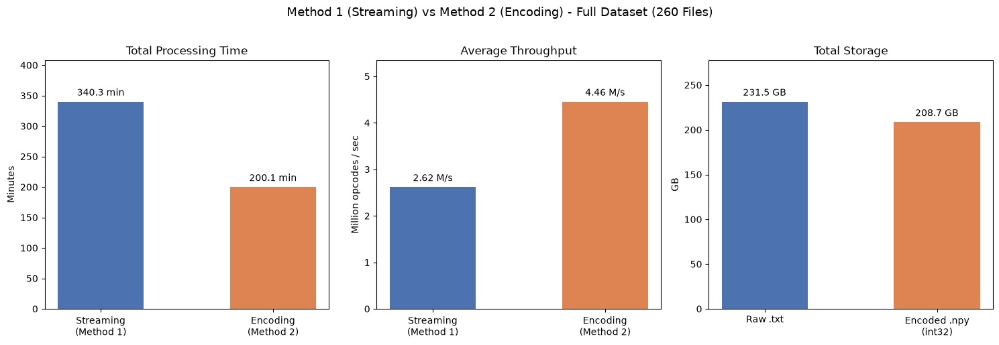

In [28]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1 - Method timing comparison
methods = ["Streaming\n(Method 1)", "Encoding\n(Method 2)"]
times = [340.3, 200.1]
bars = axes[0].bar(methods, times, color = ["#4C72B0", "#DD8452"], width=0.5)
axes[0].set_title("Total Processing Time")
axes[0].set_ylabel("Minutes")
axes[0].bar_label(bars, fmt="%.1f min", padding=4)
axes[0].set_ylim(0, max(times) * 1.2)

# Plot 2 - Throughput comparison
rates = [2_620_273, 4_457_149]
bars2 = axes[1].bar(methods, [r/1e6 for r in rates], 
                    color = ["#4C72B0", "#DD8452"], width=0.5)
axes[1].set_title("Average Throughput")
axes[1].set_ylabel("Million opcodes / sec")
axes[1].bar_label(bars2, fmt="%.2f M/s", padding=4)
axes[1].set_ylim(0, max(r/1e6 for r in rates) * 1.2)

# Plot 3 - Storage comparison 
storage_labels = ["Raw .txt", "Encoded .npy\n(int32)"]
storage_gb = [237084.1 / 1024, 213683.9 / 1024]  # MB into GB
bars3 = axes[2].bar(storage_labels, storage_gb, 
                    color = ["#4C72B0", "#DD8452"], width=0.5)
axes[2].set_title("Total Storage")
axes[2].set_ylabel("GB")
axes[2].bar_label(bars3, fmt="%.1f GB", padding=4)
axes[2].set_ylim(0, max(storage_gb) * 1.2)

plt.suptitle("Method 1 (Streaming) vs Method 2 (Encoding) - Full Dataset (260 Files)",
                fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

#### Vocabulary Breakdown

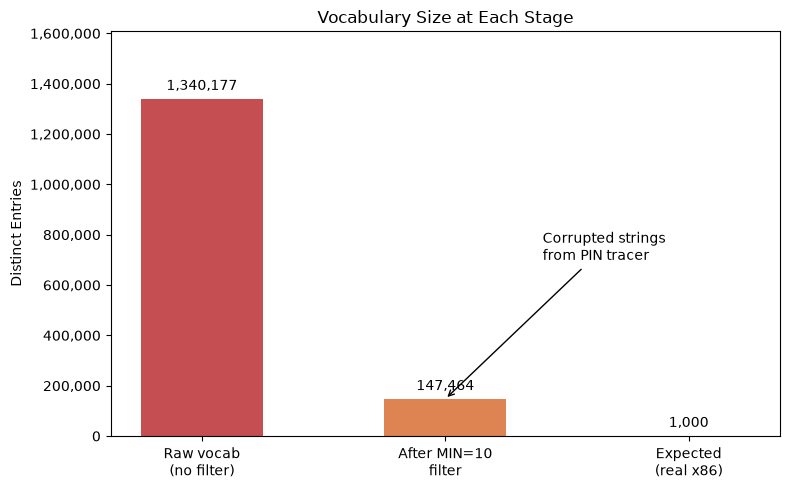

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))

vocab_stages = ["Raw vocab\n(no filter)", "After MIN=10\nfilter", "Expected\n(real x86)"]
vocab_counts = [1_340_177, 147_464, 1000]  # Roughly 1000 is a generous upper limit for real x86 mnemonics (opcode types)
colors = ["#C44E52", "#DD8452", "#4C72B0"]

bars = ax.bar(vocab_stages, vocab_counts, color=colors, width=0.5)
ax.set_title("Vocabulary Size at Each Stage")
ax.set_ylabel("Distinct Entries")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.bar_label(bars, fmt=lambda x: f"{int(x):,}", padding=4)
ax.set_ylim(0, max(vocab_counts) * 1.2)

ax.annotate("Corrupted strings\nfrom PIN tracer",
            xy=(1, 147_464), xytext=(1.4, 700_000),
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=10)

plt.tight_layout()
plt.show()

----